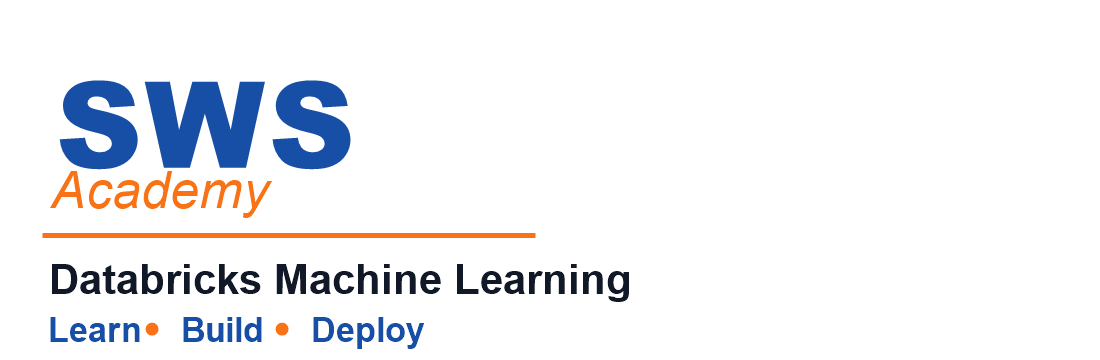


# Capstone Lab: Price Movement ModeL development at Scale (Ray-on-Spark + MLflow)

**Assignment overview - objectives & deliverables**


Build a **scalable, reproducible training workflow** that predicts next-close **price movement (UP/DOWN)** for top-traded tickers. Starting from the **clean, engineered feature table** produced in *Classroom Setup*, you will train a compact **[PyTorch MLP](https://docs.pytorch.org/vision/main/generated/torchvision.ops.MLP.html)** using **[Ray Train (TorchTrainer)](https://docs.ray.io/en/latest/train/train.html)** on Databricks and **track the end-to-end run with MLflow**. You will finish with an **honest test evaluation** and an inline **confusion matrix**. Before continuing, please make sure you have reviewed the [Capstone Project Details]($./Capstone - Project Details). 

**Deliverables**

* An **MLflow experiment** (co-located with this notebook) capturing params, metrics, and artifacts.
* A **Ray-on-Spark** training run (TorchTrainer) for a tabular **MLP classifier** built on the **Yahoo Finance Business** table.
* **Evaluation outputs** on a held-out test set: printed **Accuracy**, **F1**, and a **confusion matrix** image.
* Seeded, well-structured code that a teammate can re-run to reproduce results.

**The situation**

* **Dunder Metrics** needs a modeling path that **scales out** as data and complexity grow, while avoiding pipeline rewrites.
* *Classroom Setup* has already produced a **training-ready feature frame** with compact engineered features and a binary **`label_up`** (`1` if `CLOSING_PRICE > PREVIOUS_CLOSE`, else `0`).
* Your mandate is to **wire up MLflow**, **bring up Ray-on-Spark**, train a **small MLP**, and perform a **transparent, held-out test evaluation**, establishing a clean, production-style baseline.

**What success looks like**

1. **Correct, auditable experiment tracking**
   An MLflow experiment created beside the notebook. Each run logs parameters (epochs, learning rate, hidden sizes, batch size), validation and test metrics, and key artifacts such as a confusion matrix and an optional predictions sample.

2. **Straightforward, scalable training**
   A Ray TorchTrainer job that initializes cleanly on classic compute, consumes a Ray Dataset for training, reports validation accuracy each epoch, and preserves the best checkpoint.

3. **Honest evaluation**
   Load the best checkpoint and report Test Accuracy and F1. Render a confusion matrix and optionally log a small predictions CSV to MLflow for spot checks.

4. **Reproducibility and clarity**
   Fixed seeds, lean code, and a clean separation between feature preparation in Classroom Setup and modeling in this notebook. No leakage. `CLOSING_PRICE` is used only to define the label in setup and is not included as a feature.

**Operating constraints & expectations**

* Use **classic compute** (Ray-on-Spark is not supported on Serverless for this lab).
* Use the **prepared feature table** from Classroom Setup (e.g., `features_array`, `label_up`); identifiers/categoricals are available for joins or lightweight encodings if needed.
* Ensure **determinism** (fixed seeds), **minimal artifacts**, and **clear outputs** suitable for peer review and operational handoff.
* Keep run metadata concise and informative (short `run_name`, logged params, and final metrics).

## REQUIRED - SELECT CLASSIC COMPUTE
Before executing cells in this notebook, please select your classic compute cluster in the lab. Be aware that **Serverless** is enabled by default.

Follow these steps to select the classic compute cluster:
1. Navigate to the top-right of this notebook and click the drop-down menu to select your cluster. By default, the notebook will use **Serverless**.

1. If your cluster is available, select it and continue to the next cell. If the cluster is not shown:
    - In the drop-down, select **More**.
    - In the **Attach to an existing compute resource** pop-up, select the first drop-down. You will see a unique cluster name in that drop-down. Please select that cluster.

**NOTE:** If your cluster has terminated, you might need to restart it in order to select it. To do this:

1. Right-click on **Compute** in the left navigation pane and select *Open in new tab*.

1. Find the triangle icon to the right of your compute cluster name and click it.
1. Wait a few minutes for the cluster to start.
1. Once the cluster is running, complete the steps above to select your cluster.

## Requirements

Please review the following requirements before starting the lesson:

- To run this notebook, you need to use one of the following Databricks runtime(s): `16.4.x-cpu-ml-scala2.12`

##Classroom Setup

Run the following cell to configure your working environment for this course. It will also set your default catalog to **swsacademy** and the schema to your specific schema name shown below using the `USE` statements.
<br></br>


```
USE CATALOG swsacademy;
USE SCHEMA swsacademy.<your unique schema name>;
```

**NOTE:** The `SA` object is only used in SWSAcademy courses and is not available outside of these courses. It will dynamically reference the information needed to run the course.


**Project Setup**

This classroom setup has already prepared sources and introduced a controlled schema drift in bronze.

In [ ]:
%pip install tensorflow tensorboard torch torchvision mlflow>=3.0 databricks-feature-engineering --upgrade
%pip install -U "ray[default,rllib,tune]>=2.3.0"
dbutils.library.restartPython()

In [ ]:
%run ./Includes/Classroom-Setup-3.Capstone

**Other Conventions:**

Throughout this demo, we'll refer to the object `SA`. This object, provided by SWSAcademy, contains variables such as your username, catalog name, schema name, working directory, and dataset locations. Run the code block below to view these details:

In [ ]:
print(f"Username:          {SA.username}")
print(f"Catalog Name:      {SA.catalog_name}")
print(f"Schema Name:       {SA.schema_name}")
print(f"Working Directory: {SA.paths.working_dir}")

In [ ]:
features_table_name = f"{SA.catalog_name}.{SA.schema_name}.price_move_features"
fe = FeatureEngineeringClient()

# Load features + smoke test
df_fs = fe.read_table(name=features_table_name)
display(df_fs.limit(10))

print("Rows:", df_fs.count(), "| Cols:", len(df_fs.columns))
required_cols = ["FEATURE_ID", "features_array", "label_up"]
missing = [c for c in required_cols if c not in df_fs.columns]
assert not missing, f"Missing required columns: {missing}"

# Optional: feature length + label distribution
avg_len = df_fs.selectExpr("aggregate(features_array, 0, (acc, _) -> acc + 1) as L").agg(F.avg("L")).first()[0]
print(f"Avg feature length: {avg_len:.1f}")
display(df_fs.groupBy("label_up").count().orderBy(F.desc("count")))


## Pre-Setup - MLflow Experiment Setup (next to this notebook)

**Goal**

Create and point to an **MLflow experiment that lives alongside this notebook**, so all runs, metrics, and artifacts are organized in a predictable, team-friendly location.

**What to implement**

1. Resolve the current **notebook path**.
2. Build an experiment path in the **same directory**.
3. **Create** the experiment if it does not exist; then **set** it as active.
4. Print the final experiment path for quick verification.

**Constraints & Tips**

* This cell is **idempotent** so it’s safe tosafe to re-run.
* If the notebook path cannot be resolved (rare), use a user-scoped fallback.
* Keep run names short and informative in later tasks (e.g., `mlp_baseline_e5_b32`).

In [ ]:
import os, mlflow

try:
    nb_path = dbutils.entry_point.getDbutils().notebook().getContext().notebookPath().get()
except Exception:
    nb_path = f"/Users/{SA.username}/Capstone_Module3_Capstone_project"

experiment_path = f"{os.path.dirname(nb_path)}/Capstone_Module3_Comparison"
if mlflow.get_experiment_by_name(experiment_path) is None:
    mlflow.create_experiment(experiment_path)
mlflow.set_experiment(experiment_path)
print("MLflow experiment:", experiment_path)


## TASK 1 - Load Prepared Features & Create Deterministic Splits

**Goal**

Start from the **prepared Feature Store table** produced in Classroom Setup and get to **clean, reproducible** train/val/test partitions ready for Ray training and final evaluation.

**What to implement**

* Read minimal modeling columns from the **Feature Store**.
* Validate feature shape/label consistency.
* Create **80/20** train/test split (seed = **42**) and carve **10% of train** as validation.
* Materialize driver-side Python lists for Ray consumption (we’ll convert to Ray Dataset after Ray init).

**Constraints & Tips**

* Keep the split **deterministic** (fixed seed).
* Use only `features_array` and `label_up` (no leakage).
* Expect small, safe collects (∼1k rows) for driver-side lists.


### 1.1 - Read Feature Store Table & Sanity Check

**Goal**

Load the training-ready table, select the **minimal columns** needed for modeling, and confirm basic integrity (non-empty arrays, binary labels).

**What to implement**

1. Read the table: `FEATURE_ID`, `features_array` (array<double>), `label_up` (0/1).
2. Filter out empty or null feature arrays; enforce labels in `{0,1}`.
3. Preview a sample and print total rows + average feature length.

**Constraints & Tips**

* Use table name: `f"{SA.catalog_name}.{SA.schema_name}.price_move_features"`.
* Keep this step read-only.

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

# Import necessary modules for feature engineering and Spark SQL functions
from databricks.feature_engineering import FeatureEngineeringClient
from pyspark.sql import functions as F

# Define the feature table name using catalog and schema from the SA object
features_table_name = f"{SA.catalog_name}.{SA.schema_name}.price_move_features"
# Initialize the FeatureEngineeringClient
fe = FeatureEngineeringClient()

# Read the feature table, select necessary columns, and filter for non-null, non-empty feature arrays with valid labels
fs_df = (
    fe.read_table(name=features_table_name)
      .select("FEATURE_ID", "features_array", "label_up")
      .where(F.col("features_array").isNotNull())  # Filter out null feature arrays
      .where(F.expr("size(features_array) > 0"))   # Filter out empty feature arrays
      .where(F.col("label_up").isin(0, 1))         # Ensure labels are binary (0 or 1)
)

# Display a sample of the feature store data
print("Feature Store sample (trimmed):")
display(fs_df.limit(10))

# Calculate and print the total number of rows and average feature length
rows = fs_df.count()
avg_len = fs_df.selectExpr("size(features_array) AS L").agg(F.avg("L")).first()[0]
print(f"Rows: {rows} | Avg feature length: {avg_len:.1f}")


```
</details>


### 1.2 - Create Train/Validation/Test Splits

**Goal**

Create **deterministic** splits for training, validation, and testing.

**What to implement**

1. **80/20** train/test split with `seed=42`.
2. From the **train** split, create **90/10** train/validation (same seed).
3. Print split sizes.

**Constraints & Tips**

* Reuse `fs_df` from the prior step.
* Do not shuffle manually; rely on Spark’s `randomSplit` with a fixed seed.

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

# Perform an 80/20 train/test split on the feature store DataFrame with a fixed seed for reproducibility
train_df, test_df = fs_df.randomSplit([0.8, 0.2], seed=42)

# Further split the training DataFrame into 90/10 train/validation sets, maintaining the same seed
train_df, val_df = train_df.randomSplit([0.9, 0.1], seed=42)

# Print the sizes of each split to verify the distribution of data
print("Split sizes:")
print(f" - Train: {train_df.count()}")
print(f" - Val  : {val_df.count()}")
print(f" - Test : {test_df.count()}")


```
</details>


### 1.3 - Materialize Driver-Side Lists for Ray

**Goal**

Prepare compact **Python lists of dicts** for Ray Train input (we’ll convert train → Ray Dataset after Ray init).

**What to implement**

1. Convert each split into a list of `{"features": [float,...], "label": int}`.
2. Print lengths for a quick check.

**Constraints & Tips**

* Safe to collect at this scale (∼1k rows total).
* Keep dtype conversions explicit to avoid surprises.

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

# Convert Spark DataFrame to a list of dictionaries for Ray consumption
def to_items(sdf):
    # Collect rows from the DataFrame, selecting only the necessary columns
    rows = sdf.select("features_array", "label_up").collect()
    # Transform each row into a dictionary with 'features' and 'label' keys
    return [
        {"features": [float(x) for x in r["features_array"]], "label": int(r["label_up"])}
        for r in rows
    ]

# Convert train, validation, and test DataFrames to lists of dictionaries
train_items = to_items(train_df)
val_items   = to_items(val_df)
test_items  = to_items(test_df)

# Print the number of items in each list to verify conversion
print("Driver-side lists ready for Ray:")
print(f" - train_items: {len(train_items)}")
print(f" -  val_items: {len(val_items)}")
print(f" - test_items: {len(test_items)}")

```
</details>


### 1.4 - Compute Normalization Stats & Class Weights (from Train Split)

**Goal**

Stabilize optimization and improve minority-class recall by computing **per-feature z-score stats** (from **train** only) and **class weights** for CrossEntropy.

**What to implement**

1. Build a NumPy matrix from `train_items` and compute `feat_mean` / `feat_std`.
2. Derive class weights (`w_neg`, `w_pos`) via inverse frequency.
3. Keep these in variables for the Ray training config.

**Constraints & Tips**

* Use **train split only** to prevent leakage.
* Add a small safeguard so `feat_std` never hits zero.

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

import numpy as np

# Per-feature normalization stats (TRAIN ONLY)
X_train = np.array([it["features"] for it in train_items], dtype=np.float32)
feat_mean = X_train.mean(axis=0)  # Calculate mean for each feature
feat_std  = X_train.std(axis=0)   # Calculate standard deviation for each feature
feat_std[feat_std == 0] = 1.0  # Guard against divide-by-zero by setting zero std to 1

# Class weights (inverse-frequency)
num_pos = int(sum(it["label"] for it in train_items))  # Count positive labels
num_neg = len(train_items) - num_pos  # Count negative labels
w_pos = len(train_items) / (2.0 * max(num_pos, 1))  # Calculate weight for positive class
w_neg = len(train_items) / (2.0 * max(num_neg, 1))  # Calculate weight for negative class

# Stash as plain Python lists for Ray config serialization
feat_mean = feat_mean.astype(np.float32).tolist()  # Convert mean to list for serialization
feat_std  = feat_std.astype(np.float32).tolist()   # Convert std to list for serialization
class_weights = [float(w_neg), float(w_pos)]  # Store class weights as a list

print(f"Train size: {len(train_items)} | Pos: {num_pos} | Neg: {num_neg}")
print(f"Class weights -> w_neg: {class_weights[0]:.3f}, w_pos: {class_weights[1]:.3f}")
print(f"Feature dimension: {len(feat_mean)}")

```
</details>


## TASK 2 - Initialize Ray-on-Spark & Build the Ray Dataset

**Goal**

Bring up a **Ray cluster on your Spark compute** and convert the in-memory training split into a **Ray Dataset** that Ray Train can shard across workers.

**What to implement**

* Cleanly **shut down** any prior Ray context.
* Launch **Ray-on-Spark** with a small footprint (safe defaults).
* **Initialize** Ray and confirm the dashboard URL & resources.
* Convert `train_items` (from **TASK 1.3**) to a **Ray Dataset** and sanity-check row count & schema.

**Constraints & Tips**

* Use **classic compute** (Ray isn’t supported on Serverless for this lab).
* Keep resource requests small (e.g., `num_worker_nodes=1`, `num_cpus_per_worker=1`) so everyone in class can run.
* We’ll pass `val_items` directly to the training loop config; only the **train** split needs to be a Ray Dataset here.


### 2.1 - Clean Shutdown, Start Ray-on-Spark, and Initialize

**Goal**

Ensure a fresh Ray runtime, then bring up a small Ray-on-Spark cluster and connect the notebook to the head node.

**What to implement**

1. `ray.util.spark.shutdown_ray_cluster()` (best-effort).
2. `setup_ray_cluster(num_worker_nodes=1, num_cpus_per_worker=1)`.
3. `ray.init(...)` and print the **dashboard URL** and **cluster resources**.

**Constraints & Tips**

* It’s fine to start with a single worker; we care about **correctness + tracking**, not raw speed.
* Re-running this cell should be safe (idempotent).

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

import ray
from ray.util.spark import setup_ray_cluster

# Best-effort clean shutdowns of any existing Ray clusters
try:
    ray.util.spark.shutdown_ray_cluster()
except Exception:
    pass

try:
    ray.shutdown()
except Exception:
    pass

# Start a small Ray-on-Spark cluster with default settings
setup_ray_cluster(
    num_worker_nodes=1,
    num_cpus_per_worker=1,
    # If your cluster has GPUs and you want to try them later:
    # num_gpus_per_worker=0
)

# Initialize Ray runtime and print cluster information
context = ray.init(ignore_reinit_error=True)
print("Ray initialized.")
print("Dashboard:", context.dashboard_url)
print("Cluster resources:", ray.cluster_resources())
print("Available resources:", ray.available_resources())

```
</details>


### 2.2 - Convert Train Split to a Ray Dataset

**Goal**

Turn the Python list of dictionaries (`train_items`) into a **Ray Dataset** so Ray Train can shard it across workers.

**What to implement**

1. Use `ray.data.from_items(train_items)` to create the dataset.
2. **Shuffle** once for better stochasticity.
3. Print **row count** and show a **sample row**.
4. Capture the **feature dimension** for model construction in the next task.

**Constraints & Tips**

* `train_items` must already exist from **TASK 1.3**.
* Keep `val_items` and `test_items` as Python lists; we’ll use them directly for validation/evaluation.

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

import ray
from ray.data import from_items

# Build Ray Dataset from the driver-side list created in TASK 1.3
train_ds = from_items(train_items).random_shuffle(seed=42)

# Basic sanity checks
print("Ray Dataset (train) row count:", train_ds.count())  # Print the number of rows in the Ray Dataset
print("Schema:", train_ds.schema())  # Print the schema of the Ray Dataset
sample = train_ds.take(1)  # Take a sample record from the Ray Dataset
print("Sample record:", sample[0] if sample else "<empty>")  # Print the sample record if available

# Infer feature dimension for model definition
if sample:
    input_dim = len(sample[0]["features"])  # Determine input dimension from the sample record
else:
    # Fallback: derive from the Spark DF if needed
    input_dim = fs_df.selectExpr("size(features_array) as L").first()["L"]  # Use Spark DataFrame to infer input dimension

print("Input feature dimension:", input_dim)  # Print the inferred input feature dimension

```
</details>


## TASK 3 - Define & Run Ray TorchTrainer (MLP Baseline)

**Goal**

Train a compact **PyTorch MLP classifier** using **Ray Train (TorchTrainer)** over the Ray Dataset you created. Report **validation accuracy per epoch**, keep the **best checkpoint**, and log core **parameters/metrics** to **MLflow**.

**What to implement**

* Define a small **MLP** (`input_dim → 64 → 64 → 2`) and a **Ray Train loop** that:

  * reads a sharded training dataset via `train.get_dataset_shard("train")`
  * trains with **CrossEntropy** + **Adam**
  * evaluates on a **validation set** each epoch
  * **reports** `val_accuracy` and saves the **best** weights as a Ray **Checkpoint**
* Configure and launch **TorchTrainer** with a minimal **ScalingConfig**.
* Log **params** and **validation metrics** to **MLflow**; log the **checkpoint** as an artifact.

**Constraints & Tips**

* Keep it modest: `epochs≈5`, `batch≈32`, `hidden=64`.
* Use the **`input_dim`** detected in TASK 2.2 and **`val_items`** from TASK 1.3.
* This is a **single-worker** run (OK for the lab); scaling is a one-line change later.


### 3.1 - Define Training Configuration (Normalization & Class Weights)

**Goal**

Centralize all hyperparameters and data-dependent settings (feature dimension, z-score stats, class weights) in a single `train_config` object that the Ray train loop will consume.

**What to implement**

* Keep the MLP compact but give it a bit more runway (`epochs≈15`, `batch_size≈64`).
* Include `feat_mean`, `feat_std`, and `class_weights` computed in **Task 1.4**.
* Keep `val_items` in the config for per-epoch validation.

**Constraints & Tips**

* `input_dim` must match `len(feat_mean)`.
* `class_weights` are `[w_neg, w_pos]` and will be passed to `CrossEntropyLoss`.

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

from ray.train import ScalingConfig, RunConfig
import torch

# Sanity check for input dimension
input_dim = len(feat_mean)

train_config = {
    # Reproducibility
    "seed": 42,

    # Model shape / optimization
    "hidden1": 128,          # First hidden layer size
    "hidden2": 64,           # Second hidden layer size
    "lr": 1e-3,              # Learning rate
    "batch_size": 64,        # Batch size for training
    "epochs": 10,            # Number of training epochs
    "num_classes": 2,        # Number of output classes

    # Data-dependent config
    "input_dim": input_dim,  # Input feature dimension
    "feat_mean": feat_mean,  # Feature means for normalization
    "feat_std":  feat_std,   # Feature standard deviations for normalization
    "class_weights": class_weights,  # Class weights for loss function
    "val_items": val_items,  # Validation data items
}

# Minimal Ray scaling & run configs
scaling_config = ScalingConfig(
    num_workers=1,  # Number of worker nodes
    resources_per_worker={"CPU": 1},  # CPU resources per worker
    use_gpu=torch.cuda.is_available(),  # Use GPU if available
)

run_config = RunConfig(
    name="ray_mlp_price_move_normed",  # Run name
    storage_path="/dbfs/tmp/ray_price_move_runs",  # Storage path for run data
)
print("train_config prepared. input_dim:", input_dim)

```
</details>


### 3.2 - Define MLP & Ray Train Loop (with Standardization + Class Weights)

**Goal**

Implement a Ray Train-compatible loop that standardizes features using `feat_mean`/`feat_std`, trains with **class-weighted CrossEntropy**, validates each epoch, and checkpoints the **best** model.

**What to implement**

1. Build a compact MLP (`input_dim → 128 → 64 → 2`) with ReLU.
2. Standardize each batch: `X = (X - mean) / std`.
3. Use `nn.CrossEntropyLoss(weight=...)` with the provided class weights.
4. Report `val_accuracy` and keep a best-weights checkpoint.

**Constraints & Tips**

* Import frameworks **inside** the function so workers have the context.
* Guard device (`cuda` if available, else `cpu`).
* Report both `val_accuracy` (per epoch) and `best_val_accuracy` (running best).

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

def train_loop(config):
    from ray import train
    from ray.train import Checkpoint
    import torch
    from torch import nn
    import torch.optim as optim
    from torch.utils.data import TensorDataset, DataLoader
    import numpy as np
    import tempfile, os

    # Reproducibility
    seed = int(config.get("seed", 42))
    torch.manual_seed(seed)
    np.random.seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Model configuration
    input_dim   = int(config["input_dim"])
    hidden1     = int(config["hidden1"])
    hidden2     = int(config["hidden2"])
    num_classes = int(config["num_classes"])

    # Define the MLP model
    model = nn.Sequential(
        nn.Linear(input_dim, hidden1),
        nn.ReLU(),
        nn.Linear(hidden1, hidden2),
        nn.ReLU(),
        nn.Linear(hidden2, num_classes),
    ).to(device)

    # Optimizer and loss function (class-weighted)
    optimizer = optim.Adam(model.parameters(), lr=float(config["lr"]))
    cw = torch.tensor(config["class_weights"], dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=cw)

    # Standardization tensors
    mean_t = torch.tensor(config["feat_mean"], dtype=torch.float32, device=device)
    std_t  = torch.tensor(config["feat_std"],  dtype=torch.float32, device=device)

    # Prepare validation data loader (non-sharded)
    val_items = config.get("val_items", [])
    if len(val_items) > 0:
        Xv = torch.tensor([r["features"] for r in val_items], dtype=torch.float32)
        yv = torch.tensor([r["label"]   for r in val_items], dtype=torch.long)
        # Standardize validation features
        Xv = (Xv - mean_t.cpu()) / std_t.cpu()
        val_loader = DataLoader(TensorDataset(Xv, yv), batch_size=256, shuffle=False)
    else:
        val_loader = []

    # Get the training data shard
    shard = train.get_dataset_shard("train")
    best_val_acc, best_state = 0.0, None

    epochs     = int(config["epochs"])
    batch_size = int(config["batch_size"])

    # Training loop
    for epoch in range(epochs):
        model.train()
        for batch in shard.iter_batches(batch_size=batch_size):
            X = torch.tensor(batch["features"].tolist(), dtype=torch.float32, device=device)
            y = torch.tensor(batch["label"].tolist(),    dtype=torch.long,    device=device)

            # Standardize features
            X = (X - mean_t) / std_t

            optimizer.zero_grad()
            logits = model(X)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()

        # Validation phase
        model.eval()
        total, correct = 0, 0
        if val_loader:
            with torch.no_grad():
                for Xb, yb in val_loader:
                    Xb, yb = Xb.to(device), yb.to(device)
                    preds = model(Xb).argmax(1)
                    correct += (preds == yb).sum().item()
                    total += yb.size(0)
        val_acc = (correct / total) if total > 0 else 0.0

        # Update best validation accuracy and state
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = model.state_dict()

        # Report metrics
        train.report({"epoch": epoch, "val_accuracy": val_acc, "best_val_accuracy": best_val_acc})

    # Save the final checkpoint with best weights
    with tempfile.TemporaryDirectory() as td:
        path = os.path.join(td, "model_state_dict.pt")
        torch.save(best_state if best_state is not None else model.state_dict(), path)
        ckpt = Checkpoint.from_directory(td)
        train.report({"best_val_accuracy": best_val_acc}, checkpoint=ckpt)

```
</details>


### 3.3 - Configure & Launch TorchTrainer (with MLflow Tracking)

**Goal**

Start a **TorchTrainer** with minimal resources, run training, and log **params/metrics** (and the **checkpoint**) to **MLflow**.

**What to implement**

1. Build `ScalingConfig` (1 worker, 1 CPU; auto-detect GPU if present).
2. Fill `train_loop_config` (hyperparams + `input_dim` + `val_items`).
3. Wrap `trainer.fit()` inside `mlflow.start_run(...)`.
4. Log params, `val_accuracy_last`, `val_accuracy_best`, and the checkpoint artifact.

**Constraints & Tips**

* Use the **Ray Dataset** `train_ds` and `input_dim` from earlier tasks.
* Keep run names short and descriptive (e.g., `mlp_e5_b32_h64x64`).

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

from ray.train.torch import TorchTrainer
import mlflow, os, torch

# Initialize TorchTrainer with the training loop and configuration
trainer = TorchTrainer(
    train_loop_per_worker=train_loop,
    train_loop_config=train_config,   # from 3.0
    scaling_config=scaling_config,    # from 3.0
    datasets={"train": train_ds},     # from Task 2.2
    run_config=run_config,            # from 3.0
)

# Define the MLflow run name based on training configuration
run_name = f"mlp_std_wt_e{train_config['epochs']}_b{train_config['batch_size']}_h{train_config['hidden1']}x{train_config['hidden2']}"
with mlflow.start_run(run_name=run_name):
    # Log model parameters to MLflow
    mlflow.log_params({
        "model": "MLP",
        "hidden1": train_config["hidden1"],
        "hidden2": train_config["hidden2"],
        "lr": train_config["lr"],
        "batch_size": train_config["batch_size"],
        "epochs": train_config["epochs"],
        "input_dim": train_config["input_dim"],
        "num_workers": scaling_config.num_workers,
        "use_gpu": torch.cuda.is_available(),
        "seed": train_config["seed"],
        "normalized": True,
        "class_weighted": True,
    })

    # Launch the training process
    print("Launching Ray TorchTrainer...")
    result = trainer.fit()
    print("Training complete.")

    # Retrieve and log validation accuracy metrics
    last_val = result.metrics.get("val_accuracy")
    best_val = result.metrics.get("best_val_accuracy", last_val)
    mlflow.log_metrics({
        "val_accuracy_last": float(last_val) if last_val is not None else 0.0,
        "val_accuracy_best": float(best_val) if best_val is not None else 0.0,
    })
    print(f"Validation accuracy (last): {last_val}")
    print(f"Validation accuracy (best): {best_val}")

    # Log the best model checkpoint as an artifact
    if result.checkpoint is not None:
        with result.checkpoint.as_directory() as ck_dir:
            state_path = os.path.join(ck_dir, "model_state_dict.pt")
            if os.path.exists(state_path):
                mlflow.log_artifact(state_path, artifact_path="checkpoints")
                print("Logged checkpoint artifact:", state_path)

```
</details>


## TASK 4 - Test Evaluation & Outputs

**Goal**

Evaluate the **best checkpoint** from training on the **held-out test set**, compute **Accuracy** and **F1**, and render a **confusion matrix** inline. Log metrics and artifacts to **MLflow**.

**What to implement**

* Rebuild the **same MLP** architecture and **load** the best weights from the Ray **Checkpoint**.
* Standardize test features with the **same `feat_mean` / `feat_std`** used in training.
* Score the **test set** → collect `y_true`, `y_pred`.
* Compute and **print**: `test_accuracy` and `test_f1`.
* **Render** and **log** a confusion matrix; optionally log a small predictions CSV.

**Constraints & Tips**

* Use the **same sizes** as in TASK 3 (`input_dim`, `hidden1`, `hidden2` from `train_config`).
* Use `test_items` from TASK 1.3.
* Create a **new MLflow run** for evaluation (e.g., `eval_test`).


### 4.1 - Load Best Checkpoint, Standardize, and Score Test Set

**Goal**

Instantiate the MLP with the **same architecture**, load the **best** weights from `result.checkpoint`, **standardize** test features using `feat_mean`/`feat_std`, and compute predictions.

**What to implement**

1. Build the **MLP** with `hidden1/hidden2` from `train_config`.
2. Load `model_state_dict.pt` from `result.checkpoint`.
3. Standardize test features and run a forward pass to get `y_pred`.

**Constraints & Tips**

* Guard for `cuda` if available.
* If the checkpoint is missing (unexpected), fail loudly.

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

import os, numpy as np
import torch
from torch import nn

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Architecture from train_config (TASK 3.0)
hidden1 = int(train_config["hidden1"])
hidden2 = int(train_config["hidden2"])
input_dim = int(train_config["input_dim"])

# Rebuild MLP
mlp = nn.Sequential(
    nn.Linear(input_dim, hidden1),
    nn.ReLU(),
    nn.Linear(hidden1, hidden2),
    nn.ReLU(),
    nn.Linear(hidden2, 2),
).to(device)

# Load best checkpoint from Ray result
if result is None or result.checkpoint is None:
    raise ValueError("No checkpoint available from training run. Please re-run TASK 3.")

with result.checkpoint.as_directory() as ck_dir:
    state_path = os.path.join(ck_dir, "model_state_dict.pt")
    if not os.path.exists(state_path):
        raise FileNotFoundError(f"Checkpoint file not found at: {state_path}")
    mlp.load_state_dict(torch.load(state_path, map_location=device))
    mlp.eval()

# Prepare test tensors
X_test = torch.tensor([r["features"] for r in test_items], dtype=torch.float32)
y_test = torch.tensor([r["label"]   for r in test_items], dtype=torch.long)

# Standardize using the SAME stats as training (TASK 3.0)
mean_t = torch.tensor(train_config["feat_mean"], dtype=torch.float32)
std_t  = torch.tensor(train_config["feat_std"],  dtype=torch.float32)
X_test = (X_test - mean_t) / std_t

# Move to device
X_test = X_test.to(device)
y_test = y_test.to(device)

# Predict
with torch.no_grad():
    logits = mlp(X_test)
    y_pred = torch.argmax(logits, dim=1).cpu().numpy()

# Convert true labels to numpy array
y_true = y_test.cpu().numpy()
print(f"Scored test set: {len(y_true)} rows")

```
</details>


### 4.2 - Compute Metrics, Render Confusion Matrix, Log to MLflow

**Goal**

Compute **Accuracy** and **F1 (binary)**, render a **confusion matrix**, and log all metrics/artifacts to **MLflow**.

**What to implement**

1. Compute `accuracy_score` and `f1_score` (binary).
2. Build and display a **confusion matrix** plot using matplotlib.
3. Start a **new MLflow run**, log metrics and the confusion matrix as an artifact.
4. (Optional) Log a small predictions CSV for spot checks.

**Constraints & Tips**

* Use `labels=[0,1]` for the confusion matrix.
* Set `zero_division=0` in F1 to avoid warnings if a class is missing.

In [ ]:
<FILL_IN>

####ANSWERS
<details>
<summary>EXPAND FOR ANSWERS</summary>

```python

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import mlflow
import pandas as pd

# Compute test accuracy and F1 score
test_accuracy = float(accuracy_score(y_true, y_pred))
test_f1       = float(f1_score(y_true, y_pred, average="binary", zero_division=0))
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test F1      : {test_f1:.4f}")

# Generate confusion matrix for labels 0 and 1
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(4.0, 4.0))
im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
ax.figure.colorbar(im, ax=ax)
ax.set(xticks=[0,1], yticks=[0,1], xticklabels=[0,1], yticklabels=[0,1],
       ylabel="True label", xlabel="Predicted label", title="Confusion Matrix (Test)")
thresh = cm.max() / 2.0 if cm.size else 0.5
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, format(cm[i, j], "d"),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")
plt.tight_layout()
plt.show()

# Log metrics and confusion matrix to MLflow in a new run
with mlflow.start_run(run_name="eval_test"):
    mlflow.log_metrics({
        "test_accuracy": test_accuracy,
        "test_f1": test_f1,
    })
    mlflow.log_figure(fig, "confusion_matrix.png")

    # Optional: Log a small sample of predictions as a CSV file
    sample = pd.DataFrame({
        "row_id": np.arange(len(y_true)),
        "label_true": y_true,
        "label_pred": y_pred,
    }).head(30)
    sample_path = "predictions/preds_sample.csv"
    os.makedirs("predictions", exist_ok=True)
    sample.to_csv(sample_path, index=False)
    mlflow.log_artifact(sample_path)

    # Display the sample dataset
    display(sample)

print("Logged test metrics and artifacts to MLflow.")

```
</details>


## Wrap-Up: - Ray Cluster Cleanup & Reproducibility Summary

**Goal**

Release Ray resources cleanly and leave a short, auditable summary of what was logged to **MLflow** so teammates can find your results quickly.

**What to implement**

* Cleanly **shut down Ray-on-Spark** and confirm resources are released.
* (Optional) Print a compact **MLflow run summary** (latest training + eval) from the experiment you created in **Pre-Setup**.

**Constraints & Tips**

* This task is **idempotent**, so it's safe to re-run.
* If the MLflow listing is empty, verify you completed Tasks 3–4.


### Shutdown Ray-on-Spark

**Goal**

Stop the Ray cluster that was launched on top of Spark to avoid lingering resources.

**What to implement**

1. Call `ray.util.spark.shutdown_ray_cluster()` (best-effort).
2. Call `ray.shutdown()` and print a confirmation.

**Constraints & Tips**

* It’s fine if a prior cell already shut Ray down; handle gracefully.

In [ ]:
import ray

# Best-effort shutdown of Ray-on-Spark cluster
try:
    from ray.util.spark import shutdown_ray_cluster
    shutdown_ray_cluster()
except Exception:
    print("No active Ray-on-Spark cluster (or already shut down).")

# Shutdown Ray runtime
if ray.is_initialized():
    print("Shutting down Ray runtime…")
    ray.shutdown()

print(f"Ray initialized? {ray.is_initialized()}")


### (Optional) MLflow Run Summary (Latest Training & Eval)

**Goal**

List the **most recent runs** in your experiment to confirm key metrics (validation during training and final test metrics).

**What to implement**

1. Resolve the experiment by **path** (created in Pre-Setup).
2. Use `mlflow.search_runs` to fetch recent runs and **display** a few columns.
3. Print the experiment path for teammates.

**Constraints & Tips**

* If you changed `experiment_path` earlier, reuse the same variable here.
* Columns vary by run; select defensively.

In [ ]:
import mlflow
import pandas as pd

# Attempt to use the experiment path from Pre-Setup; fallback to active experiment if not set
try:
    experiment_path
except NameError:
    experiment = mlflow.get_experiment(mlflow.active_run().info.experiment_id) if mlflow.active_run() \
                 else mlflow.get_experiment_by_name(mlflow.get_tracking_uri())
    if experiment is not None:
        experiment_path = experiment.name
    else:
        experiment_path = None

print("Experiment path:", experiment_path if experiment_path else "<active or default>")

# Retrieve the experiment using the resolved path or fallback to the active experiment
exp = (mlflow.get_experiment_by_name(experiment_path)
       if experiment_path else mlflow.get_experiment_by_name(mlflow.get_tracking_uri()))

if exp is None:
    print("No MLflow experiment found. Re-run the Pre-Setup cell to create it (or set mlflow.set_experiment).")
else:
    # Search for the most recent runs in the experiment
    runs = mlflow.search_runs(
        experiment_ids=[exp.experiment_id],
        order_by=["start_time DESC"],
        max_results=10
    )
    if runs.empty:
        print("No runs found yet. Complete Tasks 3–4 to log training/eval.")
    else:
        # Select relevant columns to display
        cols = [c for c in [
            "run_id",
            "tags.mlflow.runName",
            "metrics.val_accuracy_last",
            "metrics.val_accuracy_best",
            "metrics.test_accuracy",
            "metrics.test_f1",
            "start_time",
            "end_time",
            "status"
        ] if c in runs.columns]
        display(runs[cols])
        print("Tip: Open the MLflow UI (Runs tab) to inspect artifacts (confusion_matrix.png, preds_sample.csv).")

***


## Conclusion

You set up an MLflow experiment and a Ray-on-Spark trainer, trained a compact PyTorch MLP on the cleaned Yahoo Finance Business features, and logged runs, metrics, and artifacts. You standardized inputs and used class weighting, reported validation each epoch, and saved the best checkpoint. On a held-out test set you computed Accuracy and F1 and rendered a confusion matrix for transparent model quality. The result is a reproducible, scalable baseline ready for iteration, including feature refinements, threshold tuning, and promotion to batch or online inference.

<div style="border-top: 1px solid #E5E7EB; margin-top: 32px; padding: 12px 0; color: #4B5563; font-size: 13px; font-family: Arial, Helvetica, sans-serif; line-height: 1.5;">
  <div><strong>SWS Academy</strong> &nbsp;|&nbsp; Databricks AI &amp; Machine Learning Course</div>
  <div>&copy; 2026 SWS Academy. All rights reserved. Unauthorized reproduction or distribution is prohibited.</div>
</div>